In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_excel("Brandon Nichols Sales and Revenue.xlsx")

df.head()

,Order Date,Ship Date,Ship Mode,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,2017-12-06 00:00:00,16/06/2017,Second Class,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,2016-11-10 00:00:00,18/10/2016,Standard Class,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,2016-11-10 00:00:00,18/10/2016,Standard Class,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
print(df.shape)
print(df.columns)
print(df.head())

(9800, 15)
Index(['Order Date', 'Ship Date', 'Ship Mode', 'Customer Name', 'Segment',
       'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID',
       'Category', 'Sub-Category', 'Product Name', 'Sales'],
      dtype='str')
            Order Date            Ship Date       Ship Mode    Customer Name  \
0  2017-08-11 00:00:00  2017-11-11 00:00:00    Second Class      Claire Gute   
1  2017-08-11 00:00:00  2017-11-11 00:00:00    Second Class      Claire Gute   
2  2017-12-06 00:00:00           16/06/2017    Second Class  Darrin Van Huff   
3  2016-11-10 00:00:00           18/10/2016  Standard Class   Sean O'Donnell   
4  2016-11-10 00:00:00           18/10/2016  Standard Class   Sean O'Donnell   

     Segment        Country             City       State  Postal Code Region  \
0   Consumer  United States        Henderson    Kentucky      42420.0  South   
1   Consumer  United States        Henderson    Kentucky      42420.0  South   
2  Corporate  United States      Los An

In [4]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

In [5]:
monthly_sales = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum().reset_index()

monthly_sales['Order Date'] = monthly_sales['Order Date'].dt.to_timestamp()

monthly_sales.head()

,Order Date,Sales
0,2015-01-01,28828.254
1,2015-02-01,12588.484
2,2015-03-01,54027.692
3,2015-04-01,24710.016
4,2015-05-01,29520.490


In [6]:
monthly_sales['Time'] = np.arange(len(monthly_sales))

X = monthly_sales[['Time']]
y = monthly_sales['Sales']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

In [8]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[640.55]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.152e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [9]:
y_pred = model.predict(X_test)

print(y_pred)

[55863.98231252 56504.53648253 57145.09065253 57785.64482254
 58426.19899255 59066.75316256 59707.30733256 60347.86150257
 60988.41567258 61628.96984259]


In [10]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)

Mean Absolute Error: 13577.917400994638
Root Mean Squared Error: 15274.693522055328
R² Score: 0.06583946436591981


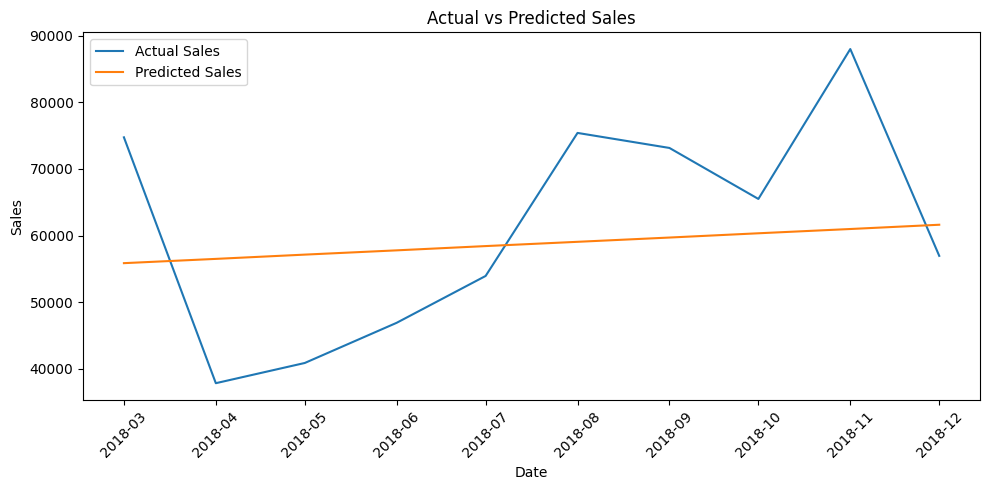

In [11]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_sales['Order Date'].iloc[len(X_train):],
    y_test,
    label='Actual Sales'
)

plt.plot(
    monthly_sales['Order Date'].iloc[len(X_train):],
    y_pred,
    label='Predicted Sales'
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Actual vs Predicted Sales")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
future_time = np.arange(
    len(monthly_sales),
    len(monthly_sales) + 6
).reshape(-1, 1)

future_predictions = model.predict(future_time)

future_dates = pd.date_range(
    start=monthly_sales['Order Date'].max() + pd.DateOffset(months=1),
    periods=6,
    freq='MS'
)

future_df = pd.DataFrame({
    'Date': future_dates,
    'Predicted Sales': future_predictions
})

print(future_df)

        Date  Predicted Sales
0 2019-01-01     62269.524013
1 2019-02-01     62910.078183
2 2019-03-01     63550.632353
3 2019-04-01     64191.186523
4 2019-05-01     64831.740693
5 2019-06-01     65472.294863


C:\Users\DELL\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


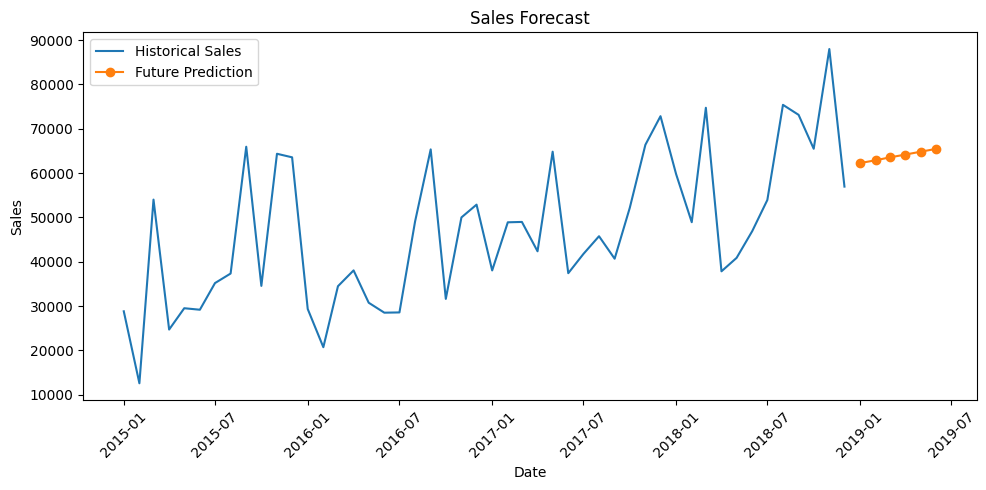

In [13]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_sales['Order Date'],
    monthly_sales['Sales'],
    label='Historical Sales'
)

plt.plot(
    future_df['Date'],
    future_df['Predicted Sales'],
    marker='o',
    label='Future Prediction'
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Sales Forecast")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()